In [2]:
from matplotlib import pyplot as plt
import numpy as np
import cv2

In [3]:
def show_cv2_image(image):
    plt.imshow(image, cmap="gray")
    plt.show()

In [4]:
def otsu_threshold(img):
    # Convert to grayscale
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    # Apply Gaussian blur
    img = cv2.GaussianBlur(img, (5, 5), 0)

    # ostu threshold
    _, ostu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return ostu

In [26]:
def split_words(img_medium, img):
    kernel = np.ones((3, 15), np.uint8)
    dilated2 = cv2.dilate(img_medium, kernel, iterations=5)
    show_cv2_image(dilated2)

    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        dilated2, connectivity=8
    )
    words = []

    # Loop through each connected component
    for i in range(1, num_labels):  # Start from 1 to skip the background
        # Extract bounding box of the component

        # sort stats by x coordinate
        stats = stats[stats[:, 0].argsort()]

        x, y, w, h, area = stats[i]

        # Ignore small components based on area if necessary
        if area < 10000:  # You can adjust the threshold
            continue

        # Extract the component
        component = img[y : y + h, x : x + w]

        words.append(component)

    return words

In [19]:
def preprocess(img):
    img_medium = otsu_threshold(img)
    img_medium = cv2.bitwise_not(img_medium)

    return img_medium

In [7]:
def remove_shadows(img):
    # https://stackoverflow.com/a/44752405
    rgb_planes = cv2.split(img)

    result_planes = []
    result_norm_planes = []
    for plane in rgb_planes:
        dilated_img = cv2.dilate(plane, np.ones((7, 7), np.uint8))
        bg_img = cv2.medianBlur(dilated_img, 21)
        diff_img = 255 - cv2.absdiff(plane, bg_img)
        norm_img = cv2.normalize(
            diff_img,
            None,
            alpha=0,
            beta=255,
            norm_type=cv2.NORM_MINMAX,
            dtype=cv2.CV_8UC1,
        )
        result_planes.append(diff_img)
        result_norm_planes.append(norm_img)

    result = cv2.merge(result_planes)
    result_norm = cv2.merge(result_norm_planes)

    return result_norm

C:/Users/Dulan/Desktop/New folder\20250319_231936.jpg


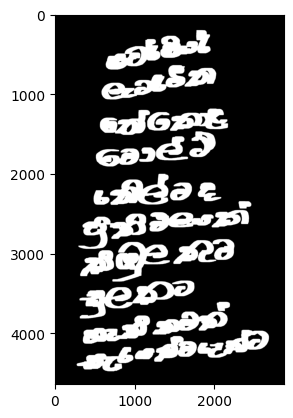

error: OpenCV(4.10.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\connectedcomponents.cpp:5624: error: (-215:Assertion failed) connectivity == 8 || connectivity == 4 in function 'cv::connectedComponents_sub1'


In [25]:
# read images in folder
import glob
import os

path = "C:/Users/Dulan/Desktop/New folder"
save_path = "C:/Users/Dulan/Desktop/New folder (2)"

for filename in glob.glob(os.path.join(path, "*.jpg")):
    print(filename)
    img = cv2.imread(filename)
    img_preprocessed = preprocess(img)
    img_split = split_words(img_preprocessed, img)
    for i in img_split:
          show_cv2_image(i)
    break
    #cv2.imwrite(os.path.join(save_path, os.path.basename(filename)), img)